> **Version formatrice.** Tous les exercices sont complétés et le notebook a été exécuté. Les participants utilisent la version à compléter, à la racine du dossier.

# IA101 — Notebook 2 — Premier modèle de classification

**Durée : 30 minutes** · Objectif visé : **O3** — entraîner un modèle avec l'interface de scikit-learn

Au notebook 1, la cible était une valeur numérique (régression). On aborde maintenant la **classification** : prédire une catégorie.

### Plan
1. Les données : les iris de Fisher
2. Séparer entraînement et test
3. L'algorithme des k plus proches voisins
4. La frontière de décision
5. Application : classification de vins et normalisation

### L'interface commune de scikit-learn

```python
X_ent, X_test, y_ent, y_test = train_test_split(X, y)   # réserver un ensemble de test
modele = Estimateur(hyperparametres)                     # instancier
modele.fit(X_ent, y_ent)                                 # entraîner
modele.predict(X_test)                                   # prédire
modele.score(X_test, y_test)                             # évaluer
```

In [1]:
# Outil de questions de vérification (exécutez cette cellule sans la modifier)
import ipywidgets as widgets
from IPython.display import display, Markdown

def quiz(question, options, bonne, explication):
    """Affiche une question à choix multiples avec rétroaction immédiate."""
    choix = widgets.RadioButtons(options=options, value=None,
                                 layout={"width": "max-content"})
    bouton = widgets.Button(description="Vérifier", button_style="primary")
    sortie = widgets.Output()

    def verifier(_):
        with sortie:
            sortie.clear_output()
            if choix.value is None:
                display(Markdown("Veuillez choisir une réponse."))
            elif choix.value == options[bonne]:
                display(Markdown(f"**Bonne réponse.** {explication}"))
            else:
                display(Markdown("**Réponse incorrecte.** Relisez la section précédente et essayez de nouveau."))

    bouton.on_click(verifier)
    display(Markdown(f"**Question de vérification.** {question}"), choix, bouton, sortie)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider
from sklearn.datasets import load_iris, load_wine
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Les données : les iris de Fisher

150 fleurs réparties en 3 espèces, décrites par 4 mesures en centimètres.

- `X` : la matrice des **variables explicatives** (une ligne par fleur, une colonne par mesure) ;
- `y` : le vecteur des **étiquettes** (l'espèce), que le modèle doit prédire.

In [3]:
iris = load_iris()
df = pd.DataFrame(iris.data, columns=["long. sépale", "larg. sépale", "long. pétale", "larg. pétale"])
df["espèce"] = [iris.target_names[i] for i in iris.target]
df.sample(6, random_state=1)

,long. sépale,larg. sépale,long. pétale,larg. pétale,espèce
14,5.8,4.0,1.2,0.2,setosa
98,5.1,2.5,3.0,1.1,versicolor
75,6.6,3.0,4.4,1.4,versicolor
16,5.4,3.9,1.3,0.4,setosa
131,7.9,3.8,6.4,2.0,virginica
56,6.3,3.3,4.7,1.6,versicolor


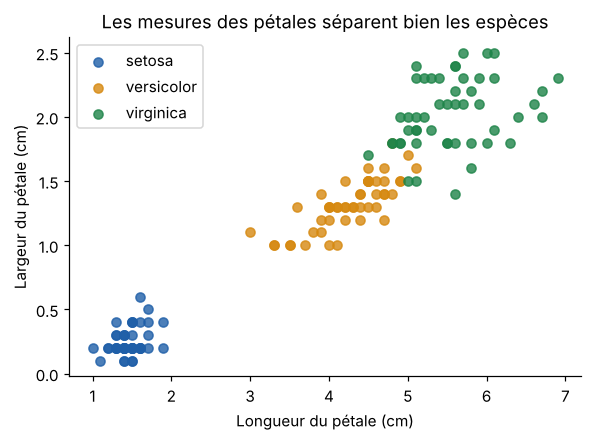

In [4]:
couleurs = ["#1f5fa8", "#d68910", "#1e8449"]
plt.figure(figsize=(6, 4))
for i, nom in enumerate(iris.target_names):
    sel = iris.target == i
    plt.scatter(iris.data[sel, 2], iris.data[sel, 3], color=couleurs[i], label=nom, alpha=0.8)
plt.xlabel("Longueur du pétale (cm)"); plt.ylabel("Largeur du pétale (cm)")
plt.title("Les mesures des pétales séparent bien les espèces"); plt.legend(); plt.show()

## 2. Séparer entraînement et test

Comme établi au notebook 1, on réserve des données pour estimer la généralisation. On conserve ici 25 % des fleurs comme ensemble de test.

- `stratify=y` conserve la proportion de chaque classe dans les deux ensembles ;
- `random_state=0` rend le découpage reproductible.

In [5]:
X = iris.data[:, 2:]          # deux variables seulement, afin de pouvoir visualiser
y = iris.target
X_ent, X_test, y_ent, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)
print(f"Entraînement : {len(X_ent)} observations | Test : {len(X_test)} observations")

Entraînement : 112 observations | Test : 38 observations


## 3. L'algorithme des k plus proches voisins (KNN)

Pour classer une nouvelle observation, le KNN identifie les **k observations d'entraînement les plus proches** (distance euclidienne) et attribue la classe **majoritaire** parmi elles.

- Le KNN ne possède pas de paramètres estimés par optimisation : il conserve les données d'entraînement.
- `k` est un **hyperparamètre** : un réglage fixé avant l'entraînement.

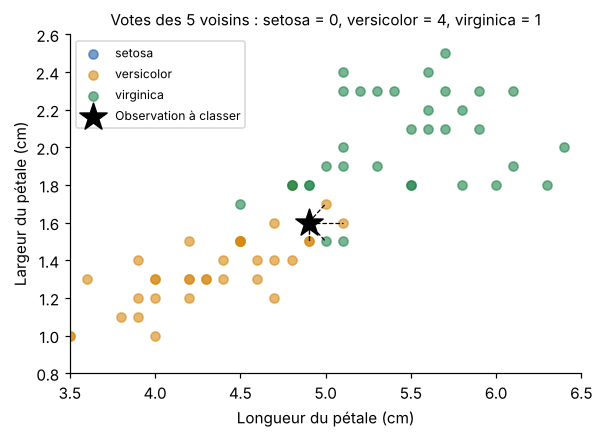

In [6]:
nouvelle = np.array([[4.9, 1.6]])
voisins = np.argsort(np.linalg.norm(X_ent - nouvelle, axis=1))[:5]

plt.figure(figsize=(6, 4))
for i, nom in enumerate(iris.target_names):
    sel = y_ent == i
    plt.scatter(X_ent[sel, 0], X_ent[sel, 1], color=couleurs[i], label=nom, alpha=0.6)
for v in voisins:
    plt.plot([nouvelle[0, 0], X_ent[v, 0]], [nouvelle[0, 1], X_ent[v, 1]], "k--", lw=0.8)
plt.scatter(*nouvelle[0], marker="*", s=350, color="black", label="Observation à classer")
plt.xlim(3.5, 6.5); plt.ylim(0.8, 2.6)
plt.xlabel("Longueur du pétale (cm)"); plt.ylabel("Largeur du pétale (cm)")
votes = np.bincount(y_ent[voisins], minlength=3)
plt.title("Votes des 5 voisins : " + ", ".join(f"{iris.target_names[i]} = {votes[i]}" for i in range(3)), fontsize=10)
plt.legend(fontsize=8); plt.show()

### Exercice 5 — Appliquer l'interface scikit-learn

Entraînez un KNN avec `k = 5`, puis calculez son **exactitude** (proportion de prédictions correctes) sur l'ensemble de test.

**Corrigé**

In [7]:
modele = KNeighborsClassifier(n_neighbors=5)
modele.fit(X_ent, y_ent)
predictions = modele.predict(X_test)
exactitude = modele.score(X_test, y_test)

print("Prédictions   :", predictions[:10])
print("Valeurs réelles :", y_test[:10])
print(f"Exactitude sur l'ensemble de test : {exactitude:.1%}")

Prédictions   : [0 0 0 0 1 1 1 0 1 2]
Valeurs réelles : [0 0 0 0 1 1 1 0 1 2]
Exactitude sur l'ensemble de test : 100.0%


## 4. La frontière de décision

En prédisant la classe de chaque point du plan, on visualise les **régions de décision** apprises par le modèle. Leur limite est la **frontière de décision**.

**Prédiction.** Avec `k = 1`, la frontière sera-t-elle plus régulière ou plus irrégulière qu'avec `k = 30` ? Quel réglage obtiendra la meilleure exactitude sur l'entraînement ?

In [8]:
from matplotlib.colors import ListedColormap

def tracer_frontiere(k=5):
    m = KNeighborsClassifier(n_neighbors=k).fit(X_ent, y_ent)
    xx, yy = np.meshgrid(np.linspace(0.5, 7.5, 300), np.linspace(-0.2, 2.8, 300))
    zz = m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    plt.figure(figsize=(6, 4))
    plt.contourf(xx, yy, zz, alpha=0.25, cmap=ListedColormap(couleurs))
    for i, nom in enumerate(iris.target_names):
        plt.scatter(X_ent[y_ent == i, 0], X_ent[y_ent == i, 1], color=couleurs[i], edgecolor="k", s=25, label=nom)
    plt.xlabel("Longueur du pétale (cm)"); plt.ylabel("Largeur du pétale (cm)")
    plt.title(f"k = {k} | exactitude entraînement : {m.score(X_ent, y_ent):.0%} | test : {m.score(X_test, y_test):.0%}")
    plt.legend(fontsize=8, loc="upper left"); plt.show()

interact(tracer_frontiere, k=IntSlider(min=1, max=60, step=1, value=1, description="k"));

interactive(children=(IntSlider(value=1, description='k', max=60, min=1), Output()), _dom_classes=('widget-int…

- **k = 1 :** chaque observation d'entraînement est sa propre voisine ; l'exactitude d'entraînement est de 100 % et la frontière suit les points isolés. Risque de **surapprentissage**.
- **k très grand :** le modèle tend vers la classe majoritaire ; risque de **sous-apprentissage**.
- La valeur appropriée se situe entre les deux. Le notebook 4 présente une méthode rigoureuse pour la choisir.

## 5. Application : classification de vins

Le jeu de données `load_wine` décrit 178 vins de 3 cultivars par **13 analyses chimiques** (alcool, acidité, intensité de la couleur, proline, etc.).

### Exercice 6a — Appliquer la démarche complète

Découpez les données (25 % en test, stratification, `random_state=0`), entraînez un KNN avec `k = 5` et calculez l'exactitude sur le test.

**Corrigé**

In [9]:
vins = load_wine()
X_vin, y_vin = vins.data, vins.target

Xv_ent, Xv_test, yv_ent, yv_test = train_test_split(
    X_vin, y_vin, test_size=0.25, stratify=y_vin, random_state=0)

knn_vin = KNeighborsClassifier(n_neighbors=5).fit(Xv_ent, yv_ent)

print(f"Exactitude sur les vins : {knn_vin.score(Xv_test, yv_test):.1%}")

Exactitude sur les vins : 66.7%


L'exactitude est nettement plus faible que sur les iris. Examinons l'**échelle** des variables.

In [10]:
echelles = pd.DataFrame(load_wine().data, columns=load_wine().feature_names).agg(["min", "max"]).T
echelles.sort_values("max", ascending=False).head(5)

,min,max
proline,278.00,1680.00
magnesium,70.00,162.00
alcalinity_of_ash,10.60,30.00
alcohol,11.03,14.83
color_intensity,1.28,13.00


La **proline** varie de 278 à 1680, tandis que la **teinte** (`hue`) varie de 0,48 à 1,71. Le KNN repose sur des distances euclidiennes : une variable de grande amplitude domine toutes les autres. Le modèle se fonde presque exclusivement sur la proline.

**Normalisation.** `StandardScaler` centre et réduit chaque variable : $z = (x - \mu) / \sigma$. Chaque variable a alors une moyenne de 0 et un écart-type de 1.

**Règle méthodologique.** Les paramètres de normalisation ($\mu$, $\sigma$) doivent être estimés **sur l'ensemble d'entraînement uniquement**, sans quoi de l'information du test « fuit » dans le modèle. Un **`Pipeline`** enchaîne prétraitement et modèle, et garantit ce comportement.

### Exercice 6b — Normaliser dans un pipeline

**Corrigé**

In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

pipeline_vin = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
pipeline_vin.fit(Xv_ent, yv_ent)
print(f"Exactitude avec normalisation : {pipeline_vin.score(Xv_test, yv_test):.1%}")

Exactitude avec normalisation : 93.3%


Le gain est important, sans changer d'algorithme : la **préparation des données** est souvent le premier levier d'amélioration d'un modèle.

In [12]:
quiz("Pourquoi réserve-t-on un ensemble de test ?",
     ["Pour accélérer l'entraînement", "Pour estimer la performance sur des données non vues", "Parce que scikit-learn l'exige"],
     1, "L'ensemble de test sert à estimer la capacité de généralisation du modèle.")

**Question de vérification.** Pourquoi réserve-t-on un ensemble de test ?

RadioButtons(layout=Layout(width='max-content'), options=("Pour accélérer l'entraînement", 'Pour estimer la pe…

Button(button_style='primary', description='Vérifier', style=ButtonStyle())

Output()

In [13]:
quiz("Où doit-on estimer la moyenne et l'écart-type utilisés par StandardScaler ?",
     ["Sur l'ensemble des données", "Sur l'ensemble d'entraînement uniquement", "Sur l'ensemble de test uniquement"],
     1, "Sinon, de l'information de l'ensemble de test influence le modèle : c'est une fuite de données. Un Pipeline évite cette erreur.")

**Question de vérification.** Où doit-on estimer la moyenne et l'écart-type utilisés par StandardScaler ?

RadioButtons(layout=Layout(width='max-content'), options=("Sur l'ensemble des données", "Sur l'ensemble d'entr…

Button(button_style='primary', description='Vérifier', style=ButtonStyle())

Output()

## À retenir

- **Classification** : prédire une catégorie ; **régression** : prédire une valeur numérique.
- Démarche : `train_test_split` → instancier → `.fit()` → `.predict()` → `.score()`.
- **KNN** : vote des k plus proches voisins ; `k` est un **hyperparamètre**.
- La **frontière de décision** révèle la complexité du modèle.
- Les méthodes fondées sur des distances exigent des variables **normalisées**, à l'intérieur d'un `Pipeline`.

**Pause de 10 minutes.** Notebook suivant : 3 — Évaluer un modèle.